# 延伸检验：λ 是不是相关系数的翻版？有没有真正的尾部联动？

接 [stock_bond_warning.ipynb](stock_bond_warning.ipynb)。主复现发现，中金的 λ_D>0 出现频率与
「相同相关强度、无尾部相关」的高斯基准不可区分。这里回答三个后续问题：

| 部分 | 问题 | 方法 |
|---|---|---|
| A | λ 携带了相关系数以外的信息吗？ | 用窗口相关系数预测 λ；用纯相关系数做同一套预警，对比效果 |
| B | 原文发表后，信号表现如何？ | 2021-02-05 之后的样本外检验 |
| C | 股债之间到底有没有超出普通相关的尾部联动？ | t-Copula 对高斯的似然比检验（ν 是否有限），加非参数的同落计数 |

**为什么用 t 对比高斯**：t-Copula 的 ρ 管整体相关，ν 管尾部厚度，ν→∞ 退化为高斯（尾部相关为 0）。
「t 是否显著好于高斯」恰好检验在同样的整体相关下，极端值是否更容易同时出现。
这是单参数 Clayton 做不到的。

## 0 · 环境与数据

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom, norm, multivariate_normal, rankdata
%run ../../01_methods.ipynb

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({
    "figure.figsize": (13, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

EQUITY, BOND = "沪深300", "中债综合财富"
IN_SAMPLE = slice("2004-04-01", "2020-12-31")     # 中金原文统计区间
OUT_SAMPLE = slice("2021-02-05", None)            # 原文发表之后

prices = load_prices([EQUITY, BOND]).loc["2003-01-01":]
returns = to_returns(prices)
print(f"{prices.index.min():%Y-%m-%d} ~ {prices.index.max():%Y-%m-%d}，共 {len(prices)} 个交易日")

2003-01-02 ~ 2026-10-12，共 5769 个交易日


In [2]:
# 与主复现同口径：60 日窗口、窗口内秩变换、点估计判零
roll = rolling_tail_dependence(returns[EQUITY], returns[BOND], window=60).loc["2004-01-01":]
dif_e = dif_trend(prices[EQUITY]).reindex(roll.index)
dif_b = dif_trend(prices[BOND]).reindex(roll.index)
fwd = returns.shift(-1).reindex(roll.index)
cicc_cond = (roll.lambda_D > 0) & (roll.lambda_U == 0)
print(f"{len(roll)} 个重估点")

5528 个重估点


---
# A · λ 携带了相关系数以外的信息吗？

## A.1 只用窗口相关系数，能多准确地预测 λ？

`ns_corr` 是同一个 60 日窗口内的正态得分相关系数（普通相关的稳健版本）。
AUC 衡量「只看相关系数，能否把 λ>0 和 λ=0 的日子分开」：0.5 = 完全分不开，1 = 完全分开。

In [3]:
def auc(y, score):
    # Mann-Whitney 形式的 AUC
    y = np.asarray(y, bool)
    r = rankdata(score)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

targets = {"λ_D>0": roll.lambda_D > 0, "λ_U>0": roll.lambda_U > 0, "中金条件（λ_D>0 且 λ_U=0）": cicc_cond}
thresholds = np.round(np.arange(-0.20, 0.30, 0.005), 3)
agree = pd.Series([((roll.ns_corr > t) == targets["λ_D>0"]).mean() for t in thresholds], index=thresholds)
CORR_THRESHOLD = agree.idxmax()

AUC_TAB = pd.DataFrame({
    "出现占比": {k: v.mean() for k, v in targets.items()},
    "仅用相关系数的 AUC": {k: auc(v, roll.ns_corr) for k, v in targets.items()},
}).style.format("{:.3f}")
AUC_TAB

,出现占比,仅用相关系数的 AUC
λ_D>0,0.309,0.953
λ_U>0,0.433,0.964
中金条件（λ_D>0 且 λ_U=0）,0.050,0.626


规则「相关系数 > 0.060」与「λ_D>0」判断一致的天数占比：88.6%


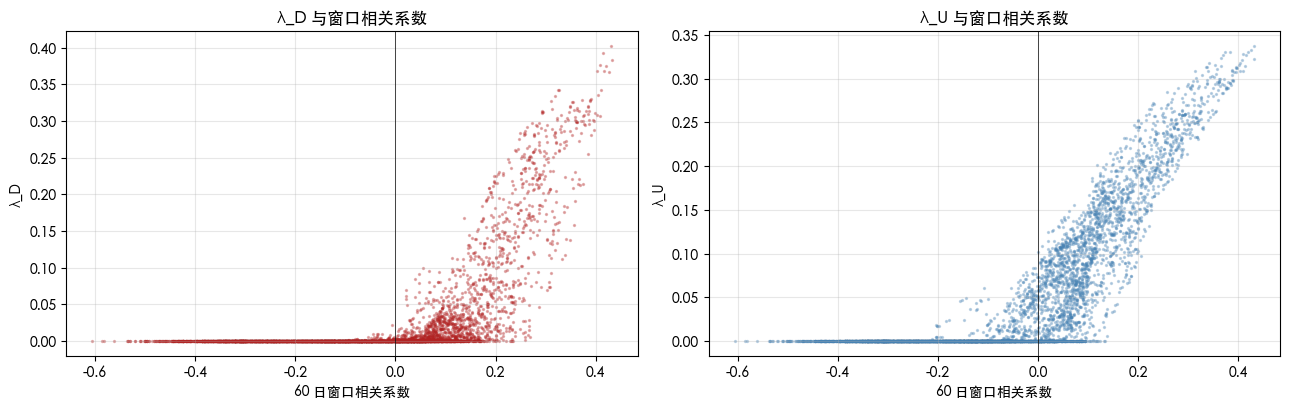

In [4]:
print(f"规则「相关系数 > {CORR_THRESHOLD:.3f}」与「λ_D>0」判断一致的天数占比：{agree.max():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(roll.ns_corr, roll.lambda_D, s=2, alpha=.3, color="firebrick")
axes[0].set_xlabel("60 日窗口相关系数"); axes[0].set_ylabel("λ_D"); axes[0].set_title("λ_D 与窗口相关系数")
axes[1].scatter(roll.ns_corr, roll.lambda_U, s=2, alpha=.3, color="steelblue")
axes[1].set_xlabel("60 日窗口相关系数"); axes[1].set_ylabel("λ_U"); axes[1].set_title("λ_U 与窗口相关系数")
for ax in axes:
    ax.axvline(0, color="k", lw=.5); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**判读**：λ_D 和 λ_U 几乎完全由窗口相关系数决定 —— 相关系数为负时两者都是 0，为正时随之增大。
中金条件只发生在相关系数略大于 0 的狭窄区间，相关系数只能部分预测它（AUC 低）；
但主复现第 4 节已经表明，这部分「额外」的波动恰好就是高斯基准下的抽样噪声。

## A.2 用纯相关系数做同一套预警

把触发条件里的「λ_D>0 且 λ_U=0」换成「窗口相关系数 > A.1 的阈值」，趋势条件与解除规则不变。
阈值取自「与 λ_D>0 最一致」，**没有按回测表现挑选**。
回测与主复现相同：月末调仓风险平价，目标波动 8%，杠杆 ≤ 4，空仓期现金年化 2%，不计交易成本。

In [5]:
sig_lambda = warning_state(roll.lambda_D, roll.lambda_U, dif_e, dif_b)
sig_corr = warning_state((roll.ns_corr > CORR_THRESHOLD).astype(float),
                            pd.Series(0.0, index=roll.index), dif_e, dif_b)

weights = risk_parity_weights(returns, lookback=60, target_vol=0.08, max_leverage=4)
base_all = portfolio_returns(weights, returns, cash_rate=0.02)

rows = {}
for period, W in [("样本内 2004–2020", IN_SAMPLE), ("样本外 2021-02 起", OUT_SAMPLE)]:
    base = base_all.loc[W]
    rows[(period, "风险平价基准")] = perf_stats(base) | {"预警天数占比": 0.0, "预警次数": 0}
    for name, s in [("中金 λ 预警", sig_lambda), ("纯相关系数预警", sig_corr)]:
        warn = to_daily(s["预警中"], base.index)
        rows[(period, name)] = (perf_stats(overlay_warning(base, warn))
                                | {"预警天数占比": warn.mean(), "预警次数": len(episodes(s["预警中"].loc[W]))})
perf = pd.DataFrame(rows).T
SIG_CMP = perf.style.format("{:.2%}", subset=["年化收益", "年化波动", "最大回撤", "预警天数占比"]).format(
    "{:.2f}", subset=["收益波动比", "超额夏普", "卡玛比率"]).format("{:.0f}", subset=["预警次数"])
SIG_CMP

**判读**（以「超额夏普」为准；「收益波动比」会因空仓期现金收益无波动而虚高）：

- 纯相关系数版本**不比中金 λ 版本差**，样本内还更好：它在股债正相关时就减仓，
  而股债正相关正是风险平价的分散效果失效的时候。
- 样本外两者都没有改善基准。
- 纯相关系数版本预警更频繁，计入交易成本后优势会缩小。

结论：λ 预警的有用部分（如果有）来自「股债转为正相关」，直接看相关系数就够了，
「λ_U=0」这个尾部条件没有带来额外价值。

---
# B · 样本外：原文发表之后

原文 2021-02-05 发表。之后的数据完全没有参与原文的设计，是对其结论最干净的检验。

In [6]:
def scenario_table(mask, W):
    m = mask.loc[W].fillna(False).astype(bool)
    f = fwd.loc[W]
    out = {}
    for name, mm in [("全部日子", pd.Series(True, index=m.index)), ("情景③ 中金条件", m)]:
        fe, fb = f.loc[mm, EQUITY].dropna(), f.loc[mm, BOND].dropna()
        out[name] = {"样本天数": int(mm.sum()),
                     "股票次日均收益": fe.mean(), "t_股": fe.mean() / fe.std() * np.sqrt(len(fe)),
                     "债券次日均收益": fb.mean(), "t_债": fb.mean() / fb.std() * np.sqrt(len(fb))}
    return pd.DataFrame(out).T

pd.concat({"样本内": scenario_table(cicc_cond, IN_SAMPLE),
           "样本外": scenario_table(cicc_cond, OUT_SAMPLE)}).style.format(
    {"股票次日均收益": "{:.3%}", "债券次日均收益": "{:.3%}", "t_股": "{:.2f}", "t_债": "{:.2f}", "样本天数": "{:.0f}"})

In [7]:
r_oos = roll.loc[OUT_SAMPLE]
null = gaussian_null(window=60, n_sims=6000, seed=1)
exp_oos = expected_under_gaussian(r_oos, null)
pd.DataFrame({
    "实测": [(r_oos.lambda_D > 0).mean(), cicc_cond.loc[OUT_SAMPLE].mean()],
    "匹配相关强度的高斯基准": [exp_oos["lambda_D>0"].mean(), exp_oos["中金条件"].mean()],
}, index=["λ_D>0 占比", "中金条件占比"]).style.format("{:.2%}")

,实测,匹配相关强度的高斯基准
λ_D>0 占比,22.45%,18.25%
中金条件占比,5.83%,2.73%


In [8]:
print("样本外的中金预警事件：")
episodes(sig_lambda["预警中"].loc[OUT_SAMPLE])

样本外的中金预警事件：


,触发,解除,持续交易日
0,2021-07-09,2021-07-14,4
1,2021-11-03,2021-12-07,25
2,2022-05-11,2022-05-23,9
3,2023-11-28,2024-01-11,32
4,2026-08-05,2026-08-31,19
5,2026-09-03,2026-09-09,5
6,2026-09-22,2026-09-22,1
7,2026-09-28,2026-09-29,2


**判读**：

- 样本外情景③依然不是股债双负：股票次日收益约为 0，债券显著为正。原文的核心证据在发表后的数据上没有得到支持。
- 与样本内不同，样本外中金条件的出现频率约为匹配基准的 2 倍。但相邻 60 日窗口几乎完全重叠，
  1372 个交易日里真正独立的窗口只有二十来个，这一差异的统计意义有限；更重要的是，
  即便它多出现了，出现之后也没有跟随股债双杀。

---
# C · 股债之间有没有超出普通相关的尾部联动？

## C.1 检验本身是否可靠

在纯高斯数据（尾部相关严格为 0）上跑同一个检验，5% 水平下应约有 5% 的窗口误报。

In [9]:
size = pd.DataFrame({rho: (gaussian_null_t_test(window=250, n_sims=300, rho=rho, seed=i).p_t < 0.05).mean()
                     for i, rho in enumerate([-0.3, 0.0, 0.3])}, index=["5% 水平误报率"])
SIZE_T = size.style.format("{:.1%}")
SIZE_T

,-0.300000,0.000000,0.300000
5% 水平误报率,4.3%,5.7%,4.3%


## C.2 逐年检验（互不重叠的年度窗口）

每个自然年单独检验，年与年之间互不重叠，拒绝次数可以直接用二项分布判断显著性。
同时给出非参数的「同落」比例：股票落在当年最差 10% 的日子里，债券也落在最差 10% 的比例，
以及在当年相关系数下高斯 Copula 给出的期望值。

In [10]:
Q = 0.10
z = norm.ppf(Q)

def gaussian_coexceed(rho):
    # 高斯 Copula 下 P(V≤q | U≤q)，上尾由对称性相同
    return multivariate_normal([0, 0], [[1, rho], [rho, 1]]).cdf([z, z]) / Q

rows = []
for year, g in returns.groupby(returns.index.year):
    if len(g) < 200:
        continue
    u, v = rank_pit(g[EQUITY].values), rank_pit(g[BOND].values)
    res = t_vs_gaussian(u, v)
    lo, hi = u <= Q, u > 1 - Q
    rows.append({"年份": year, "天数": len(g), "ρ": res["rho"], "ν": res["nu"], "p 值": res["p_t"],
                 "t 隐含尾部相关": res["lambda_t"],
                 "股尾天数": int(lo.sum()),
                 "下尾同落": int((v[lo] <= Q).sum()), "上尾同落": int((v[hi] > 1 - Q).sum()),
                 "高斯期望同落": lo.sum() * gaussian_coexceed(res["rho"])})
yearly = pd.DataFrame(rows).set_index("年份")
yearly.style.format({"ρ": "{:.2f}", "ν": "{:.1f}", "p 值": "{:.3f}", "t 隐含尾部相关": "{:.1%}",
                     "高斯期望同落": "{:.1f}"})

,天数,ρ,ν,p 值,t 隐含尾部相关,股尾天数,下尾同落,上尾同落,高斯期望同落
年份,,,,,,,,,
2003,240,0.02,200.0,1.000,0.0%,24,5,1,2.6
2004,243,0.06,60.0,0.421,0.0%,24,4,5,2.9
2005,242,-0.15,37.4,0.363,0.0%,24,1,1,1.4
2006,241,-0.00,25.9,0.300,0.0%,24,5,2,2.4
2007,242,0.18,194.7,1.000,0.0%,24,4,1,3.9
2008,246,0.01,6.1,0.023,3.5%,24,5,4,2.5
2009,244,0.02,8.1,0.086,1.7%,24,2,6,2.6
2010,242,0.01,7.2,0.069,2.3%,24,4,3,2.5
2011,244,-0.03,7.9,0.055,1.3%,24,1,4,2.2


In [11]:
n_years = len(yearly)
summary = []
for alpha in (0.05, 0.10):
    k = int((yearly["p 值"] < alpha).sum())
    summary.append({"显著性水平": alpha, "拒绝高斯的年数": k, "纯运气下的期望年数": n_years * alpha,
                    "二项检验 p 值": binom.sf(k - 1, n_years, alpha)})
BINOM_T = pd.DataFrame(summary).style.format({"显著性水平": "{:.0%}", "纯运气下的期望年数": "{:.1f}",
                                    "二项检验 p 值": "{:.4f}"})
BINOM_T

,显著性水平,拒绝高斯的年数,纯运气下的期望年数,二项检验 p 值
0,5%,4,1.2,0.0258
1,10%,11,2.3,0.0000


## C.3 方向：极端时是「一起跌」还是只是「一起剧烈波动」？

t-Copula 上下尾对称，ν 显著有限只说明极端值倾向于同日出现。
中金关心的是**同日下跌**，所以要分别数下尾和上尾的同落次数，与高斯期望对比。

In [12]:
exp_total = yearly["高斯期望同落"].sum()
direction = pd.DataFrame({
    "实际同落次数": [yearly["下尾同落"].sum(), yearly["上尾同落"].sum()],
    "高斯期望": [exp_total, exp_total],
}, index=["下尾：股债同日落入最差 10%", "上尾：股债同日落入最好 10%"])
direction["超出倍数"] = direction["实际同落次数"] / direction["高斯期望"]
direction["z 值（泊松近似）"] = (direction["实际同落次数"] - direction["高斯期望"]) / np.sqrt(direction["高斯期望"])
direction.style.format({"高斯期望": "{:.1f}", "超出倍数": "{:.2f}", "z 值（泊松近似）": "{:.2f}"})

,实际同落次数,高斯期望,超出倍数,z 值（泊松近似）
下尾：股债同日落入最差 10%,57,47.5,1.20,1.38
上尾：股债同日落入最好 10%,55,47.5,1.16,1.09


## C.4 稳健性：剥离波动率共振

两个市场在同一段时间都高波动（方向随机），也会让 ν 变小。
先用前 60 日滚动波动率标准化收益（只用截至前一日的信息），再重做逐年检验。

In [13]:
scaled = (returns / returns.rolling(60).std().shift(1)).dropna()
rows = []
for year, g in scaled.groupby(scaled.index.year):
    if len(g) < 200:
        continue
    res = t_vs_gaussian(rank_pit(g[EQUITY].values), rank_pit(g[BOND].values))
    rows.append({"年份": year, "ρ": res["rho"], "ν": res["nu"], "p 值": res["p_t"]})
yearly_scaled = pd.DataFrame(rows).set_index("年份")
k = int((yearly_scaled["p 值"] < 0.05).sum())
print(f"波动率标准化后：{k}/{len(yearly_scaled)} 年在 5% 水平拒绝高斯，"
      f"二项检验 p = {binom.sf(k - 1, len(yearly_scaled), 0.05):.4f}")
yearly_scaled.T.style.format("{:.2f}")

波动率标准化后：7/22 年在 5% 水平拒绝高斯，二项检验 p = 0.0001


年份,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
ρ,0.07,-0.14,0.00,0.21,-0.00,-0.01,0.00,-0.05,-0.14,0.07,-0.01,-0.05,0.11,0.07,-0.21,-0.25,-0.22,0.03,-0.13,-0.19,-0.29,-0.31
ν,11.60,20.68,15.92,200.00,5.77,200.00,6.16,7.57,26.01,12.25,8.18,200.00,4.18,7.07,19.66,4.98,9.25,7.89,6.40,9.34,4.54,9.75
p 值,0.17,0.24,0.20,1.00,0.02,1.00,0.03,0.05,0.32,0.16,0.04,1.00,0.00,0.06,0.27,0.01,0.11,0.07,0.03,0.09,0.00,0.09


## C.5 滚动 250 日窗口

窗口相互重叠，拒绝比例不能直接与 5% 比较（相邻窗口高度相关），只用来看时间分布。
每 5 个交易日重估一次。

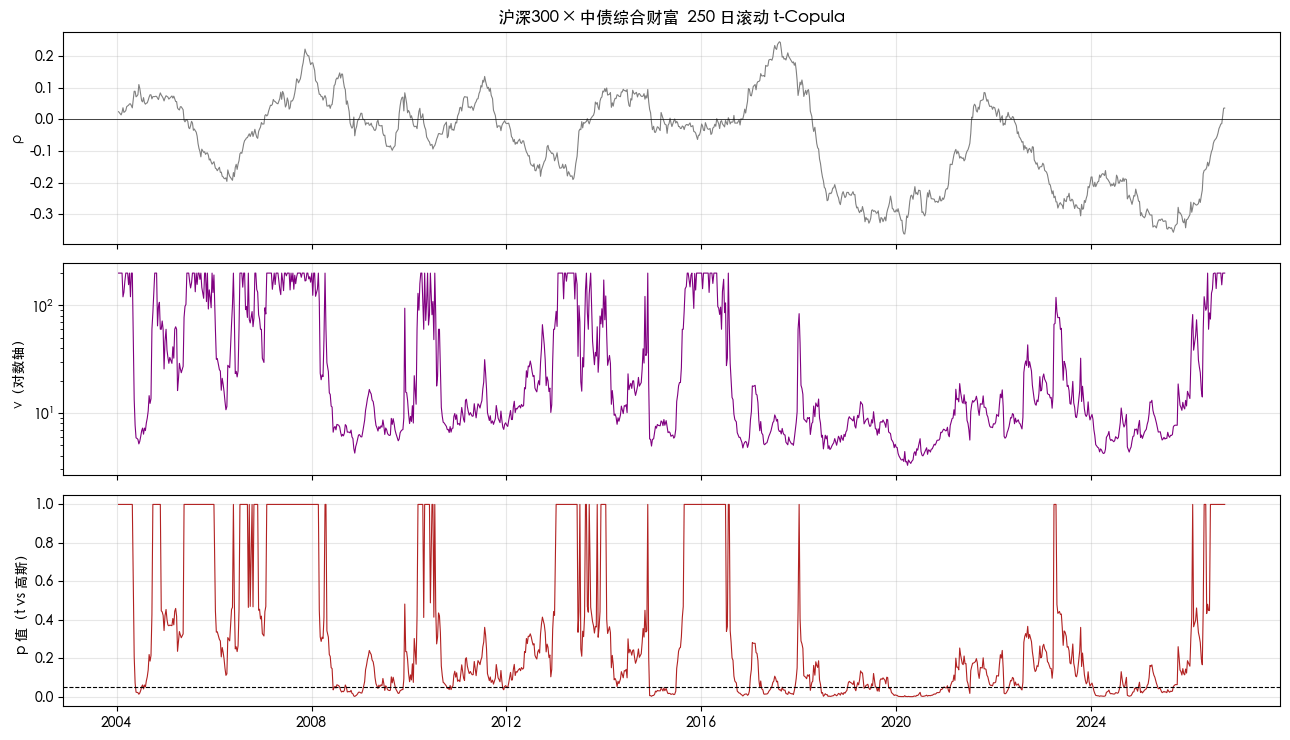

1104 个窗口中 p<0.05 的占比 26.4%；t 隐含尾部相关的中位数 0.19%，90% 分位 3.15%


In [14]:
rt = rolling_t_test(returns[EQUITY], returns[BOND], window=250, step=5)
fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
axes[0].plot(rt.index, rt.rho, lw=.8, color="gray"); axes[0].axhline(0, color="k", lw=.5)
axes[0].set_ylabel("ρ")
axes[1].semilogy(rt.index, rt.nu, lw=.8, color="purple"); axes[1].set_ylabel("ν（对数轴）")
axes[2].plot(rt.index, rt.p_t, lw=.8, color="firebrick"); axes[2].axhline(0.05, color="k", ls="--", lw=.8)
axes[2].set_ylabel("p 值（t vs 高斯）")
axes[0].set_title(f"{EQUITY} × {BOND}  250 日滚动 t-Copula")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"{len(rt)} 个窗口中 p<0.05 的占比 {(rt.p_t < 0.05).mean():.1%}；"
      f"t 隐含尾部相关的中位数 {rt.lambda_t.median():.2%}，90% 分位 {rt.lambda_t.quantile(.9):.2%}")

---
# 结论

| 问题 | 结论 |
|---|---|
| A. λ 携带了相关系数以外的信息吗 | **基本没有**。λ_D、λ_U 几乎完全由窗口相关系数决定；把预警条件换成纯相关系数，样本内超额夏普更高、样本外持平 |
| B. 原文发表后信号表现如何 | **核心证据仍不成立**。情景③股票次日约为 0、债券显著为正 |
| C. 有没有超出普通相关的尾部联动 | **有一点，但很弱且不分方向**。逐年检验拒绝高斯的年数显著多于运气（波动率标准化后更明显），但隐含尾部相关多在 0–4%；同日落入最差 10% 与最好 10% 的次数都只比高斯多约两成，均不显著。股债极端值略倾向于同日出现，但看不出「同日下跌」多于「同日上涨」 |

下方为自动汇总的关键数字。

In [15]:
k05 = int((yearly["p 值"] < 0.05).sum())
lo, up, ex = direction["实际同落次数"].iloc[0], direction["实际同落次数"].iloc[1], direction["高斯期望"].iloc[0]
print(f"A. λ_D>0 与「相关系数>{CORR_THRESHOLD:.3f}」一致 {agree.max():.1%}，"
      f"AUC {auc(targets['λ_D>0'], roll.ns_corr):.3f}")
print(f"B. 样本外情景③ {int(cicc_cond.loc[OUT_SAMPLE].sum())} 天，"
      f"股票次日 {fwd.loc[OUT_SAMPLE][cicc_cond.loc[OUT_SAMPLE]][EQUITY].mean():.3%}，"
      f"债券次日 {fwd.loc[OUT_SAMPLE][cicc_cond.loc[OUT_SAMPLE]][BOND].mean():.3%}")
print(f"C. {k05}/{n_years} 年拒绝高斯（期望 {n_years * .05:.1f}）；"
      f"下尾同落 {lo} 次 / 上尾同落 {up} 次 / 高斯期望 {ex:.1f} 次")

A. λ_D>0 与「相关系数>0.060」一致 88.6%，AUC 0.953
B. 样本外情景③ 80 天，股票次日 -0.022%，债券次日 0.028%
C. 4/23 年拒绝高斯（期望 1.2）；下尾同落 57 次 / 上尾同落 55 次 / 高斯期望 47.5 次


In [16]:
save_table("lambda_auc", AUC_TAB)
save_table("corr_vs_lambda_signal", SIG_CMP)
save_table("t_test_size", SIZE_T)
save_table("t_test_yearly", yearly)
save_table("t_test_binom", BINOM_T)
save_table("coexceed_direction", direction)
save_table("t_test_yearly_scaled", yearly_scaled)